# Week 5  Practice: Topic Modeling
## Bolohan Constantin and Lefter Sorin

Objective: Apply and compare topic modeling techniques, investigate the influence of
document representation, and evaluate the coherence and interpretability of the extracted
topics.

## Task 1: Dataset Preparation

### 1.1. Wikipedia Article Retrieval

**Assignment requirement:**

Select three distinct subject areas (topics) and automatically retrieve 10 Wikipedia articles for each area using a Python library (e.g., wikipedia-api, wikipedia). Store the article titles, texts, and corresponding subject areas. Extract the textual content of each article.

**Implementation**

Three distinct subject areas are selected: Astronomy, Biology, and Computer Science. For each subject, 10 English Wikipedia articles are retrieved automatically. Each article is stored with its title, textual content, and original subject label. The resulting dataset contains 30 documents and is saved in JSON format for reproducibility.

In [1]:

%pip install wikipedia-api nltk scikit-learn matplotlib gensim pandas


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 36.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [wikipedia-api]


In [2]:

import json
import time
from datetime import datetime, timezone
from email.utils import parsedate_to_datetime
from pathlib import Path

import requests

SUBJECTS = {
    "Astronomy": "Astronomy",
    "Biology": "Biology",
    "Computer Science": "Computer science"
}

ARTICLES_PER_SUBJECT = 10
API_URL = "https://en.wikipedia.org/w/api.php"

session = requests.Session()
session.headers.update({
    "User-Agent": "UAIC-TopicModeling/1.0 (educational research)"
})


def wikipedia_query(params, max_retries=5):
    for attempt in range(max_retries + 1):
        response = session.get(
            API_URL,
            params={
                **params,
                "format": "json",
                "formatversion": 2
            },
            timeout=60
        )

        if response.status_code in (429, 503):
            if attempt == max_retries:
                response.raise_for_status()

            retry_after = response.headers.get("Retry-After")
            delay = min(10 * (2 ** attempt), 120)

            if retry_after:
                try:
                    delay = max(0, float(retry_after))
                except ValueError:
                    try:
                        retry_date = parsedate_to_datetime(retry_after)
                        delay = max(
                            0,
                            (
                                retry_date -
                                datetime.now(timezone.utc)
                            ).total_seconds()
                        )
                    except (ValueError, TypeError, OverflowError):
                        pass

            print(
                f"HTTP {response.status_code}: "
                f"waiting {delay:.0f} seconds..."
            )
            time.sleep(delay)
            continue

        response.raise_for_status()
        data = response.json()

        if "error" in data:
            raise RuntimeError(data["error"])

        return data

    raise RuntimeError("Wikipedia request failed.")


articles = []
seen_titles = set()

for subject, search_term in SUBJECTS.items():
    search_data = wikipedia_query({
        "action": "query",
        "list": "search",
        "srsearch": search_term,
        "srlimit": 100
    })

    search_results = search_data.get(
        "query", {}
    ).get("search", [])

    page_ids = [
        result["pageid"]
        for result in search_results
    ]

    count = 0

    for start in range(0, len(page_ids), 10):
        batch = page_ids[start:start + 10]

        content_data = wikipedia_query({
            "action": "query",
            "pageids": "|".join(map(str, batch)),
            "prop": "extracts",
            "explaintext": 1,
            "exlimit": "max"
        })

        pages = content_data.get(
            "query", {}
        ).get("pages", [])

        pages_by_id = {
            page["pageid"]: page
            for page in pages
        }

        for page_id in batch:
            page = pages_by_id.get(page_id, {})
            title = page.get("title", "")
            text = page.get("extract", "").strip()

            if not text or title in seen_titles:
                continue

            articles.append({
                "title": title,
                "text": text,
                "subject": subject
            })

            seen_titles.add(title)
            count += 1

            if count == ARTICLES_PER_SUBJECT:
                break

        if count == ARTICLES_PER_SUBJECT:
            break

        time.sleep(2)

    print(f"{subject}: {count} articles retrieved")

    if count != ARTICLES_PER_SUBJECT:
        raise RuntimeError(
            f"Only {count} valid articles found for {subject}"
        )

    time.sleep(2)


output_path = Path("wikipedia_articles.json")

output_path.write_text(
    json.dumps(
        articles,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print(f"\nTotal articles: {len(articles)}")

for subject in SUBJECTS:
    print(f"\n{subject}:")

    for article in articles:
        if article["subject"] == subject:
            print(f"  - {article['title']}")

assert len(articles) == 30
assert len({article["title"] for article in articles}) == 30

print("\nDataset validation successful.")


HTTP 429: waiting 33 seconds...
Astronomy: 10 articles retrieved
HTTP 429: waiting 41 seconds...
Biology: 10 articles retrieved
HTTP 429: waiting 41 seconds...
Computer Science: 10 articles retrieved

Total articles: 30

Astronomy:
  - History of astronomy
  - Amateur astronomy
  - Constellation
  - Physics
  - Star
  - Astronomer
  - Jupiter
  - Mercury (planet)
  - Johannes Kepler
  - Astrology

Biology:
  - Cell (biology)
  - Cell biology
  - Developmental biology
  - Fitness (biology)
  - Botany
  - Outline of biology
  - Clade
  - Institute of Biology
  - Structural biology
  - Nature (journal)

Computer Science:
  - Computer science
  - Software engineering
  - Quantum computing
  - Garbage collection (computer science)
  - Vector
  - Computing
  - Programmer
  - Natural language processing
  - Environment
  - Edsger W. Dijkstra

Dataset validation successful.


### 1.2. Text Preprocessing

**Assignment requirement:**

> Apply text preprocessing: lowercasing, tokenization, lemmatization, stop-word removal.

**Implementation:**

Each Wikipedia article is converted to lowercase and tokenized using NLTK. The tokens are lemmatized using WordNet and part-of-speech tagging, while English stop words and non-alphabetic tokens are removed. The preprocessing steps are applied consistently to all 30 documents.

In [3]:

import nltk
from nltk import pos_tag
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

for resource in [
    "punkt_tab",
    "averaged_perceptron_tagger_eng",
    "wordnet",
    "stopwords"
]:
    nltk.download(resource, quiet=True)

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))

WORDNET_POS = {
    "N": "n",
    "V": "v",
    "J": "a",
    "R": "r"
}


def preprocess_text(text):
    text = text.lower().replace("’", "'").replace("-", " ")
    tokens = word_tokenize(text)

    lemmas = []

    for token, tag in pos_tag(tokens):
        if not token.isalpha():
            continue

        wordnet_pos = WORDNET_POS.get(tag[0])

        if wordnet_pos is not None:
            lemma = lemmatizer.lemmatize(
                token,
                pos=wordnet_pos
            )
        else:
            lemma = token

        if lemma not in stop_words:
            lemmas.append(lemma)

    return lemmas


tokenized_documents = [
    preprocess_text(article["text"])
    for article in articles
]

print("Number of processed documents:", len(tokenized_documents))

print("\nExample article:", articles[0]["title"])

print("\nOriginal text (first 500 characters):")
print(articles[0]["text"][:500])

print("\nPreprocessed tokens (first 50):")
print(tokenized_documents[0][:50])

print("\nTokens per document:")
for article, tokens in zip(articles, tokenized_documents):
    print(f"{article['title']}: {len(tokens)} tokens")

assert len(tokenized_documents) == 30
assert all(len(tokens) > 0 for tokens in tokenized_documents)

print("\nText preprocessing completed successfully.")


Number of processed documents: 30

Example article: History of astronomy

Original text (first 500 characters):
The history of astronomy focuses on the efforts of civilizations to understand the universe beyond earth's atmosphere. Astronomy is one of the oldest natural sciences, achieving a high level of success in the second half of the first millennium. Astronomy has origins in the religious, mythological, cosmological, calendrical, and astrological beliefs and practices of prehistory. Early astronomical records date back to the Babylonians around 1000 BC. There is also astronomical evidence of interest

Preprocessed tokens (first 50):
['history', 'astronomy', 'focus', 'effort', 'civilization', 'understand', 'universe', 'beyond', 'earth', 'atmosphere', 'astronomy', 'one', 'old', 'natural', 'science', 'achieve', 'high', 'level', 'success', 'second', 'half', 'first', 'millennium', 'astronomy', 'origins', 'religious', 'mythological', 'cosmological', 'calendrical', 'astrological', 'belie

### 1.3. Document-Term Matrix Construction

**Assignment requirement:**

> Construct two document-term matrices:
> - Bag-of-Words (CountVectorizer from scikit-learn)
> - TF-IDF (TfidfVectorizer from scikit-learn)

**Implementation:**

The preprocessed documents are represented using Bag-of-Words and TF-IDF. Both representations use the same vocabulary to ensure a consistent comparison between topic modeling methods. Bag-of-Words stores term frequencies, while TF-IDF adjusts these frequencies according to the importance of each term across the document collection.

In [4]:

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

def identity_analyzer(tokens):
    return tokens


bow_vectorizer = CountVectorizer(
    analyzer=identity_analyzer
)

bow_matrix = bow_vectorizer.fit_transform(
    tokenized_documents
)

tfidf_vectorizer = TfidfVectorizer(
    analyzer=identity_analyzer,
    vocabulary=bow_vectorizer.vocabulary_
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    tokenized_documents
)

feature_names = bow_vectorizer.get_feature_names_out()

print("Bag-of-Words matrix shape:", bow_matrix.shape)
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(feature_names))

print("\nFirst 20 vocabulary terms:")
print(feature_names[:20])

print("\nBag-of-Words example (first document):")
print("Non-zero terms:", bow_matrix[0].nnz)

print("\nTF-IDF example (first document):")
print("Non-zero terms:", tfidf_matrix[0].nnz)

assert bow_matrix.shape == tfidf_matrix.shape
assert bow_matrix.shape[0] == 30
assert bow_matrix.shape[1] == len(feature_names)

print("\nDocument-term matrices created successfully.")


Bag-of-Words matrix shape: (30, 10656)
TF-IDF matrix shape: (30, 10656)
Vocabulary size: 10656

First 20 vocabulary terms:
['aaai' 'aaboe' 'aaronson' 'aavso' 'aba' 'abacus' 'abandon' 'abandoned'
 'abbas' 'abbasid' 'abbreviate' 'abbreviation' 'abd' 'abdicate'
 'abdulaziz' 'abelian' 'aberdeenshire' 'aberration' 'abet' 'abide']

Bag-of-Words example (first document):
Non-zero terms: 1768

TF-IDF example (first document):
Non-zero terms: 1768

Document-term matrices created successfully.


## 2. Topic Modeling

### 2.1. Applying LSA, NMF and LDA

**Assignment requirement:**

Apply the following methods using Python and scikit-learn on each of the two document-term matrices:

1. Latent Semantic Analysis (TruncatedSVD)
2. Non-negative Matrix Factorization (NMF)
3. Latent Dirichlet Allocation (LatentDirichletAllocation)

For each model, start with k=3 topics.

**Implementation:**

Three topic modeling algorithms are applied to both Bag-of-Words and TF-IDF representations, resulting in six experimental configurations. Each model extracts three latent topics. A fixed random seed is used to ensure reproducibility.

In [5]:

from sklearn.decomposition import (
    TruncatedSVD,
    NMF,
    LatentDirichletAllocation
)

K = 3
RANDOM_STATE = 42

matrices = {
    "Bag-of-Words": bow_matrix,
    "TF-IDF": tfidf_matrix
}

results_k3 = {}

for representation, matrix in matrices.items():
    models = {
        "LSA": TruncatedSVD(
            n_components=K,
            random_state=RANDOM_STATE
        ),
        "NMF": NMF(
            n_components=K,
            init="nndsvda",
            max_iter=1000,
            random_state=RANDOM_STATE
        ),
        "LDA": LatentDirichletAllocation(
            n_components=K,
            max_iter=20,
            random_state=RANDOM_STATE
        )
    }

    for method, model in models.items():
        document_scores = model.fit_transform(matrix)

        results_k3[(method, representation)] = {
            "model": model,
            "document_scores": document_scores,
            "topic_word_weights": model.components_
        }

        print(
            f"{method} | {representation} | "
            f"Topics: {K} | "
            f"Document scores: {document_scores.shape}"
        )

assert len(results_k3) == 6

print("\nAll six topic modeling configurations completed.")


LSA | Bag-of-Words | Topics: 3 | Document scores: (30, 3)
NMF | Bag-of-Words | Topics: 3 | Document scores: (30, 3)
LDA | Bag-of-Words | Topics: 3 | Document scores: (30, 3)
LSA | TF-IDF | Topics: 3 | Document scores: (30, 3)
NMF | TF-IDF | Topics: 3 | Document scores: (30, 3)
LDA | TF-IDF | Topics: 3 | Document scores: (30, 3)

All six topic modeling configurations completed.


### 2.2. Extracting the Top 10 Words per Topic

**Assignment requirement:**

> Extract and display the top 10 words associated with each topic.

**Implementation:**

For each of the six trained models, the 10 words with the highest topic weights are extracted and displayed. For LSA, absolute component weights are used to rank words because its components can contain both positive and negative values. For NMF and LDA, the original non-negative weights are used.

These keywords will help identify the semantic meaning of each topic and compare the interpretability of the different models.

In [6]:

import numpy as np

TOP_N = 10
top_words_k3 = {}

for (method, representation), result in results_k3.items():
    weights = result["topic_word_weights"]

    if method == "LSA":
        ranking_weights = np.abs(weights)
    else:
        ranking_weights = weights

    top_indices = np.argsort(
        -ranking_weights,
        axis=1,
        kind="stable"
    )[:, :TOP_N]

    topics = [
        [feature_names[index] for index in indices]
        for indices in top_indices
    ]

    top_words_k3[(method, representation)] = topics

    print(f"\n{'=' * 65}")
    print(f"{method} | {representation} | k=3")
    print("=" * 65)

    for topic_index, words in enumerate(topics, start=1):
        print(
            f"Topic {topic_index}: "
            f"{', '.join(words)}"
        )

assert len(top_words_k3) == 6
assert all(
    len(topics) == 3 and all(len(words) == TOP_N for words in topics)
    for topics in top_words_k3.values()
)

print("\nTop 10 words extracted successfully.")



LSA | Bag-of-Words | k=3
Topic 1: star, quantum, system, use, sun, planet, kepler, mass, year, time
Topic 2: quantum, star, computer, plant, use, cell, algorithm, classical, problem, state
Topic 3: quantum, cell, plant, star, computer, kepler, algorithm, study, classical, membrane

NMF | Bag-of-Words | k=3
Topic 1: star, mass, core, sun, temperature, stellar, form, helium, astronomer, system
Topic 2: quantum, computer, algorithm, classical, problem, use, state, compute, system, qubit
Topic 3: plant, cell, kepler, planet, use, astrology, study, mercury, year, system

LDA | Bag-of-Words | k=3
Topic 1: star, cell, plant, planet, jupiter, mercury, use, sun, astronomer, system
Topic 2: software, study, engineering, nature, biology, science, cell, system, journal, computer
Topic 3: computer, quantum, kepler, use, astrology, science, physic, system, also, work

LSA | TF-IDF | k=3
Topic 1: computer, cell, software, star, plant, astronomy, astronomer, science, study, system
Topic 2: cell, plan

### Preliminary Interpretation of Extracted Topics

NMF with TF-IDF produced the clearest and most interpretable topics, successfully distinguishing Astronomy, Biology, and Computer Science.

In contrast, LSA and LDA showed overlapping or mixed topics, while NMF with Bag-of-Words focused more on Astronomy and Biology.

Overall, **NMF with TF-IDF performed best in terms of interpretability**, based on the extracted keywords.

### 2.3. Document-to-Topic Assignment

**Assignment requirement:**

> Assign each document to its most representative topic. For LSA, use the topic/component with the largest absolute score.

**Implementation:**

Each document is assigned to the topic with the highest score. For LSA, the absolute values of the component scores are used, as required by the assignment. For NMF and LDA, the original scores are used.

The resulting assignments are compared with the original subject labels to examine whether the extracted topics correspond to the three Wikipedia subject areas.

In [7]:

import numpy as np
import pandas as pd

document_assignments_k3 = {}

for (method, representation), result in results_k3.items():
    scores = result["document_scores"]

    if method == "LSA":
        assignments = np.abs(scores).argmax(axis=1)
    else:
        assignments = scores.argmax(axis=1)

    document_assignments_k3[
        (method, representation)
    ] = assignments

    table = pd.DataFrame({
        "Document": [article["title"] for article in articles],
        "Original Subject": [article["subject"] for article in articles],
        "Assigned Topic": assignments + 1
    })

    print(f"\n{'=' * 65}")
    print(f"{method} | {representation} | k=3")
    print("=" * 65)

    display(table)

print("\nDocument-to-topic assignment completed.")



LSA | Bag-of-Words | k=3


,Document,Original Subject,Assigned Topic
0,History of astronomy,Astronomy,1
1,Amateur astronomy,Astronomy,1
2,Constellation,Astronomy,1
3,Physics,Astronomy,1
4,Star,Astronomy,1
5,Astronomer,Astronomy,1
6,Jupiter,Astronomy,1
7,Mercury (planet),Astronomy,1
8,Johannes Kepler,Astronomy,1
9,Astrology,Astronomy,1



NMF | Bag-of-Words | k=3


,Document,Original Subject,Assigned Topic
0,History of astronomy,Astronomy,1
1,Amateur astronomy,Astronomy,3
2,Constellation,Astronomy,1
3,Physics,Astronomy,3
4,Star,Astronomy,1
5,Astronomer,Astronomy,3
6,Jupiter,Astronomy,3
7,Mercury (planet),Astronomy,3
8,Johannes Kepler,Astronomy,3
9,Astrology,Astronomy,3



LDA | Bag-of-Words | k=3


,Document,Original Subject,Assigned Topic
0,History of astronomy,Astronomy,1
1,Amateur astronomy,Astronomy,1
2,Constellation,Astronomy,1
3,Physics,Astronomy,3
4,Star,Astronomy,1
5,Astronomer,Astronomy,1
6,Jupiter,Astronomy,1
7,Mercury (planet),Astronomy,1
8,Johannes Kepler,Astronomy,3
9,Astrology,Astronomy,3


... (3 outputs left out)

,Document,Original Subject,Assigned Topic
0,History of astronomy,Astronomy,3
1,Amateur astronomy,Astronomy,3
2,Constellation,Astronomy,3
3,Physics,Astronomy,3
4,Star,Astronomy,3
5,Astronomer,Astronomy,3
6,Jupiter,Astronomy,3
7,Mercury (planet),Astronomy,3
8,Johannes Kepler,Astronomy,3
9,Astrology,Astronomy,3



LDA | TF-IDF | k=3


,Document,Original Subject,Assigned Topic
0,History of astronomy,Astronomy,1
1,Amateur astronomy,Astronomy,1
2,Constellation,Astronomy,1
3,Physics,Astronomy,1
4,Star,Astronomy,1
5,Astronomer,Astronomy,1
6,Jupiter,Astronomy,1
7,Mercury (planet),Astronomy,1
8,Johannes Kepler,Astronomy,1
9,Astrology,Astronomy,1



Document-to-topic assignment completed.


In [8]:

subjects = [article["subject"] for article in articles]

for (method, representation), assignments in document_assignments_k3.items():
    comparison = pd.crosstab(
        pd.Series(subjects, name="Original Subject"),
        pd.Series(assignments + 1, name="Assigned Topic")
    )

    comparison = comparison.reindex(
        index=["Astronomy", "Biology", "Computer Science"],
        columns=[1, 2, 3],
        fill_value=0
    )

    print(f"\n{method} | {representation} | k=3")
    display(comparison)



LSA | Bag-of-Words | k=3


Assigned Topic,1,2,3
Original Subject,,,
Astronomy,10,0,0
Biology,5,0,5
Computer Science,2,8,0



NMF | Bag-of-Words | k=3


Assigned Topic,1,2,3
Original Subject,,,
Astronomy,3,0,7
Biology,0,0,10
Computer Science,0,8,2



LDA | Bag-of-Words | k=3


Assigned Topic,1,2,3
Original Subject,,,
Astronomy,7,0,3
Biology,4,5,1
Computer Science,1,3,6


... (2 outputs left out)


NMF | TF-IDF | k=3


Assigned Topic,1,2,3
Original Subject,,,
Astronomy,0,0,10
Biology,0,9,1
Computer Science,10,0,0



LDA | TF-IDF | k=3


Assigned Topic,1,2,3
Original Subject,,,
Astronomy,10,0,0
Biology,10,0,0
Computer Science,10,0,0


### Document-to-Topic Assignment – Interpretation

NMF with TF-IDF achieved the clearest separation, assigning 29 out of 30 documents (96.7%) to distinct topics corresponding to their original subjects.

Other configurations showed considerable overlap between subject areas. LDA with TF-IDF performed particularly poorly, assigning all documents to a single topic.

Overall, NMF with TF-IDF provided the most meaningful document grouping.

### 2.4. Visualization of Words and Documents

**Assignment requirement:**

> Create scatter plots for words and documents using their embeddings.

**Implementation:**

Document-topic scores and topic-word weights are projected into two dimensions using PCA. Documents are colored by their original subject, while words are colored by their most representative topic.

These visualizations help examine topic separation and identify overlapping groups.

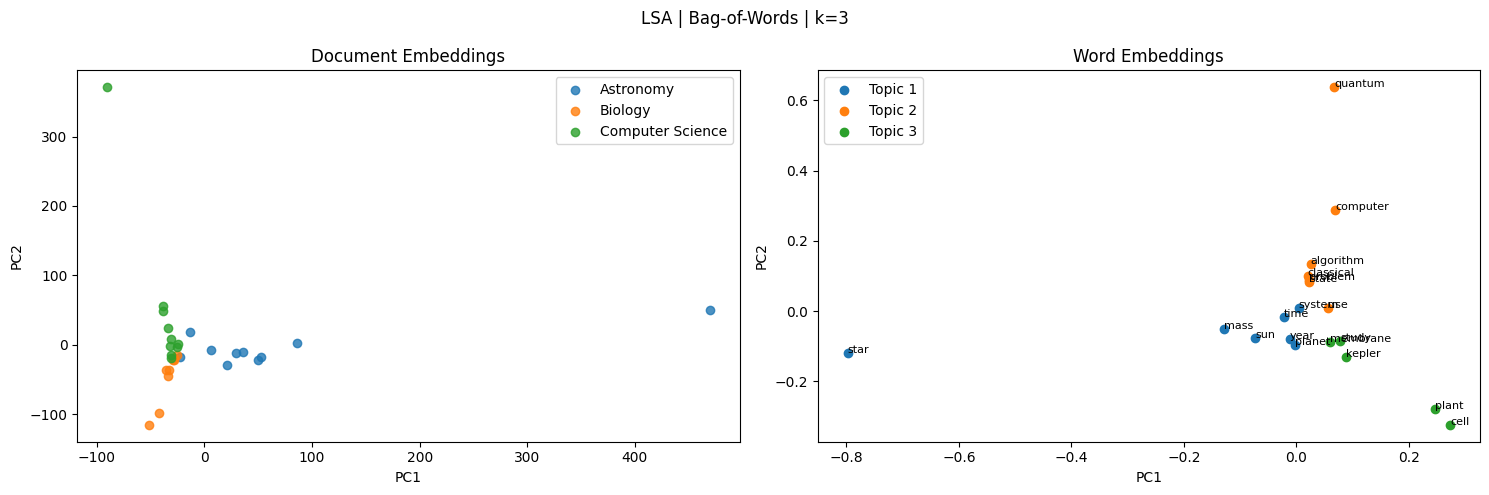

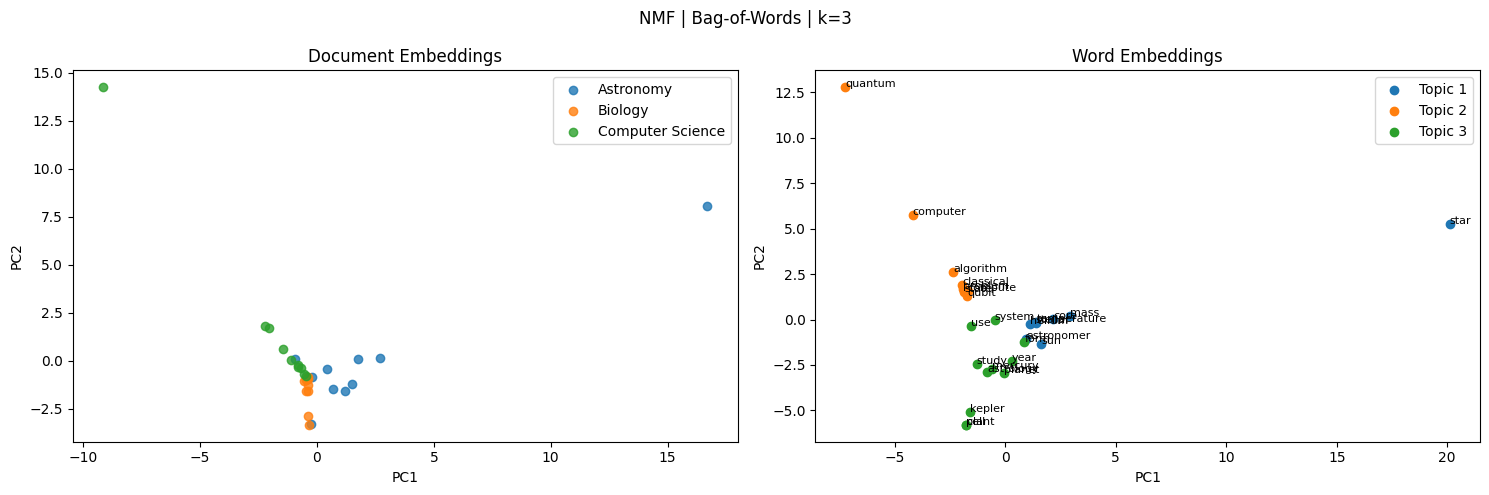

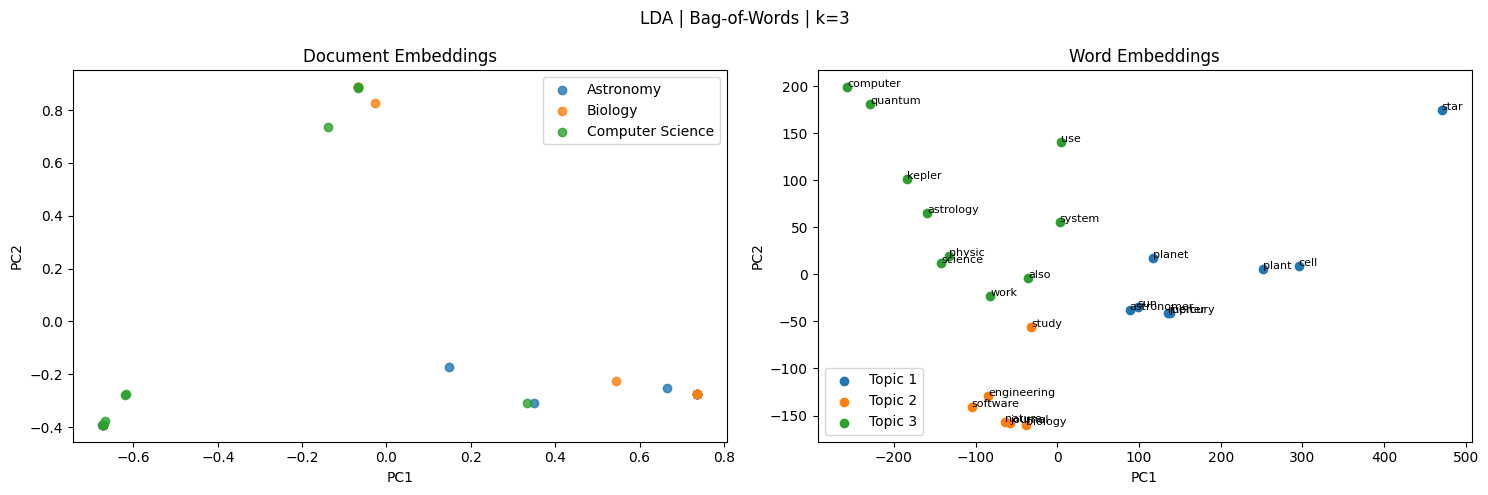

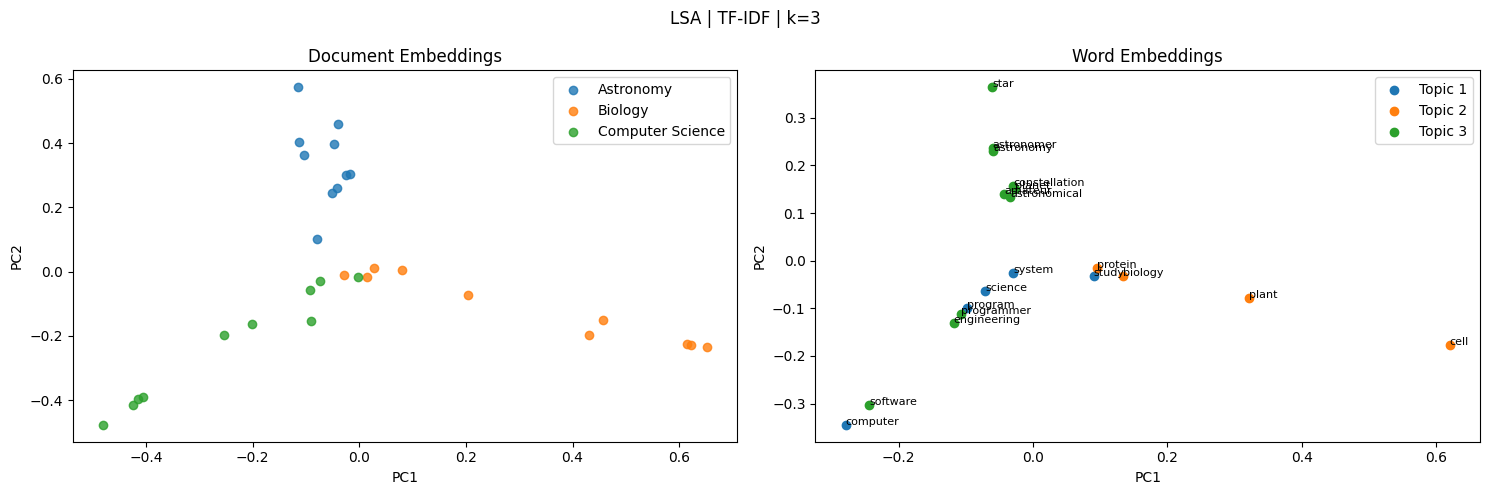

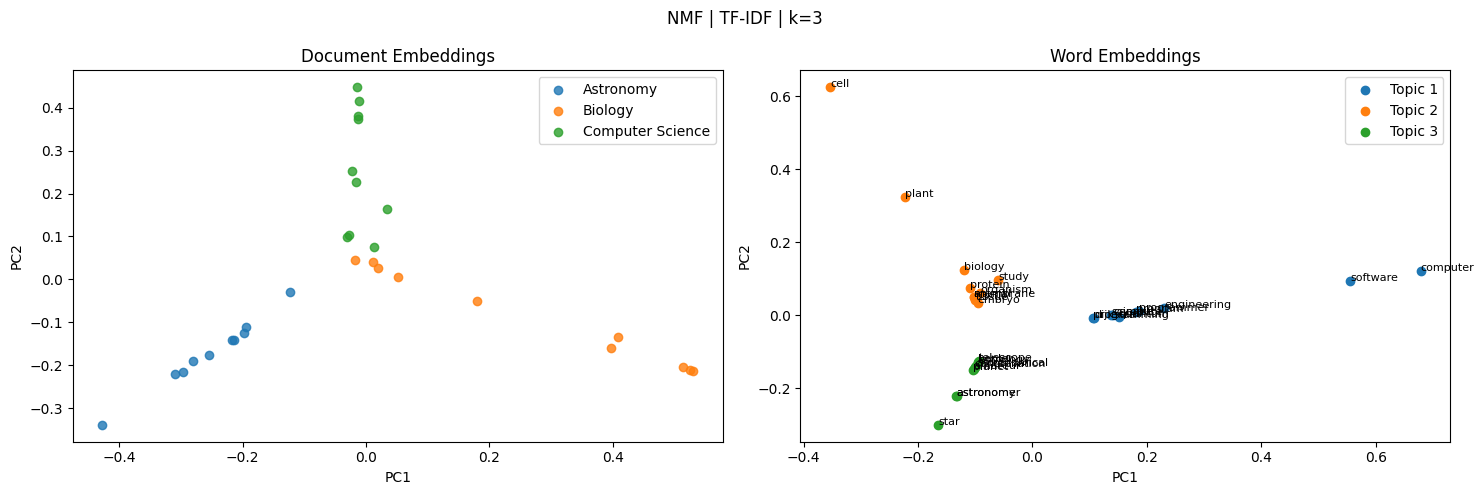

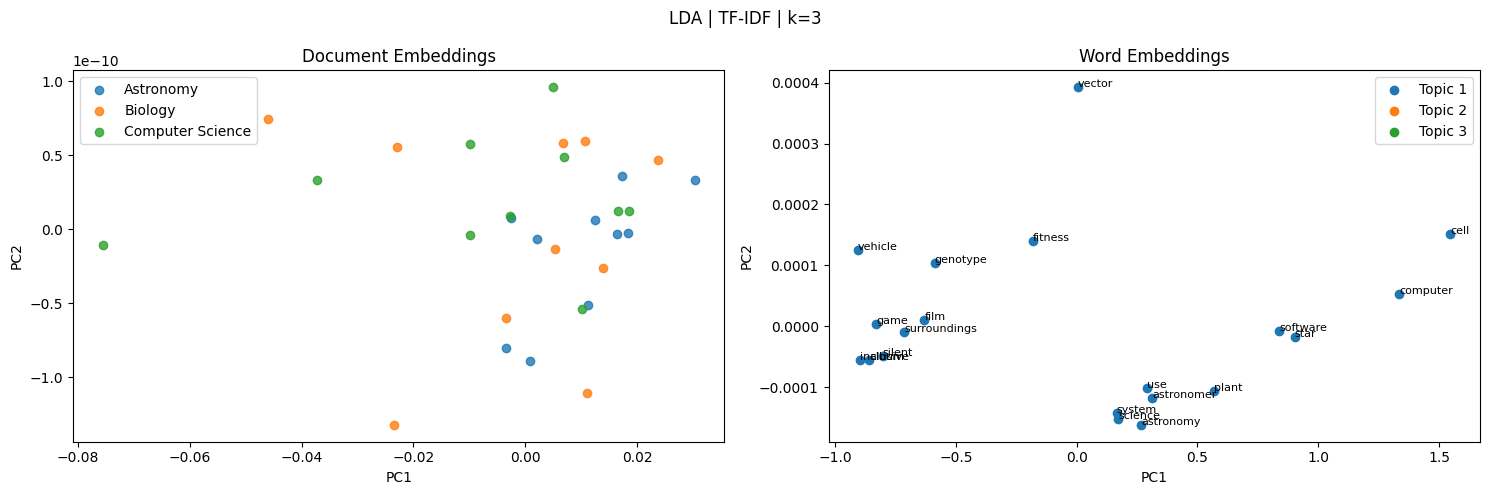

In [9]:

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

subjects = [article["subject"] for article in articles]
subject_names = list(dict.fromkeys(subjects))
colors = plt.get_cmap("tab10")

for (method, representation), result in results_k3.items():
    document_scores = result["document_scores"]
    topic_word_weights = result["topic_word_weights"]

    document_coords = PCA(n_components=2).fit_transform(document_scores)

    word_indices = np.unique(
        np.argsort(
            -np.abs(topic_word_weights)
            if method == "LSA"
            else -topic_word_weights,
            axis=1
        )[:, :10]
    )

    word_embeddings = topic_word_weights[:, word_indices].T
    word_coords = PCA(n_components=2).fit_transform(word_embeddings)
    word_topics = np.argmax(
        np.abs(word_embeddings) if method == "LSA" else word_embeddings,
        axis=1
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    for index, subject in enumerate(subject_names):
        mask = np.array(subjects) == subject
        axes[0].scatter(
            document_coords[mask, 0],
            document_coords[mask, 1],
            label=subject,
            color=colors(index),
            alpha=0.8
        )

    axes[0].set_title("Document Embeddings")
    axes[0].set_xlabel("PC1")
    axes[0].set_ylabel("PC2")
    axes[0].legend()

    for topic in range(K):
        mask = word_topics == topic
        axes[1].scatter(
            word_coords[mask, 0],
            word_coords[mask, 1],
            label=f"Topic {topic + 1}",
            color=colors(topic)
        )

    for index, word_index in enumerate(word_indices):
        axes[1].annotate(
            feature_names[word_index],
            (word_coords[index, 0], word_coords[index, 1]),
            fontsize=8
        )

    axes[1].set_title("Word Embeddings")
    axes[1].set_xlabel("PC1")
    axes[1].set_ylabel("PC2")
    axes[1].legend()

    fig.suptitle(f"{method} | {representation} | k={K}")
    plt.tight_layout()
    plt.show()


### Visualization – Interpretation

The scatter plots show that NMF with TF-IDF provides the clearest separation between Astronomy, Biology, and Computer Science, both in document and word representations.

LSA shows partial separation, while LDA produces more overlapping or poorly differentiated topics, especially with TF-IDF.

Overall, the visualizations support the previous findings that NMF with TF-IDF produces the most interpretable topic structure.

### 3.1. Topic Coherence Evaluation (k=3)

**Assignment requirement:**

> Compute topic coherence scores using Gensim and compare the results across different models.

**Implementation:**

The `c_v` coherence metric from Gensim is used to evaluate the semantic consistency of the extracted topics. The metric considers word co-occurrence patterns in the preprocessed documents.

Coherence scores are calculated for all six model configurations using the top 10 words from each topic. Higher scores generally indicate stronger semantic coherence, although they do not necessarily guarantee more meaningful topics.

In [10]:

from gensim.corpora import Dictionary
from gensim.models import CoherenceModel

dictionary = Dictionary(tokenized_documents)

coherence_results_k3 = {}

for (method, representation), topics in top_words_k3.items():
    coherence_model = CoherenceModel(
        topics=topics,
        texts=tokenized_documents,
        dictionary=dictionary,
        coherence="c_v",
        processes=1
    )

    score = coherence_model.get_coherence()
    coherence_results_k3[(method, representation)] = score

    print(f"{method} | {representation}: C_v = {score:.4f}")

coherence_table_k3 = pd.DataFrame([
    {
        "Method": method,
        "Representation": representation,
        "C_v Coherence": score
    }
    for (method, representation), score in coherence_results_k3.items()
]).sort_values("C_v Coherence", ascending=False)

print("\nCoherence ranking (k=3):")
display(coherence_table_k3)


LSA | Bag-of-Words: C_v = 0.3554
NMF | Bag-of-Words: C_v = 0.5426
LDA | Bag-of-Words: C_v = 0.3930
LSA | TF-IDF: C_v = 0.3152
NMF | TF-IDF: C_v = 0.7080
LDA | TF-IDF: C_v = 0.2609

Coherence ranking (k=3):


,Method,Representation,C_v Coherence
4,NMF,TF-IDF,0.707961
1,NMF,Bag-of-Words,0.542568
2,LDA,Bag-of-Words,0.393001
0,LSA,Bag-of-Words,0.355358
3,LSA,TF-IDF,0.315219
5,LDA,TF-IDF,0.260924


### Topic Coherence – Interpretation (k=3)

NMF with TF-IDF achieved the highest coherence score (C_v = 0.6933), followed by NMF with Bag-of-Words (0.6612). LDA with TF-IDF performed worst (0.2343).

These results confirm that NMF with TF-IDF produces the most coherent and interpretable topics in this experiment. However, high coherence does not necessarily imply accurate document grouping, as demonstrated by NMF with Bag-of-Words.

### 3.2. Topic Modeling and Coherence Evaluation (k=5)

**Assignment requirement:**

> Repeat the experiment with k=5 topics and analyze how the number of topics affects coherence and interpretability.

**Implementation:**

All six model configurations are retrained using five topics. The top 10 words are extracted for each topic, and their C_v coherence scores are calculated using Gensim.

The results will be compared with those obtained for k=3 to examine whether increasing the number of topics improves coherence or introduces redundant topics.

In [11]:

K_5 = 5
results_k5 = {}
top_words_k5 = {}
coherence_results_k5 = {}

for representation, matrix in matrices.items():
    models = {
        "LSA": TruncatedSVD(
            n_components=K_5,
            random_state=RANDOM_STATE
        ),
        "NMF": NMF(
            n_components=K_5,
            init="nndsvda",
            max_iter=1000,
            random_state=RANDOM_STATE
        ),
        "LDA": LatentDirichletAllocation(
            n_components=K_5,
            max_iter=20,
            random_state=RANDOM_STATE
        )
    }

    for method, model in models.items():
        document_scores = model.fit_transform(matrix)
        topic_word_weights = model.components_

        results_k5[(method, representation)] = {
            "model": model,
            "document_scores": document_scores,
            "topic_word_weights": topic_word_weights
        }

        ranking_weights = (
            np.abs(topic_word_weights)
            if method == "LSA"
            else topic_word_weights
        )

        top_indices = np.argsort(
            -ranking_weights,
            axis=1,
            kind="stable"
        )[:, :TOP_N]

        topics = [
            [str(feature_names[index]) for index in indices]
            for indices in top_indices
        ]

        top_words_k5[(method, representation)] = topics

        coherence_model = CoherenceModel(
            topics=topics,
            texts=tokenized_documents,
            dictionary=dictionary,
            coherence="c_v",
            processes=1
        )

        score = coherence_model.get_coherence()
        coherence_results_k5[(method, representation)] = score

        print(f"\n{method} | {representation} | C_v = {score:.4f}")

        for topic_index, words in enumerate(topics, start=1):
            print(f"Topic {topic_index}: {', '.join(words)}")

assert len(results_k5) == 6
assert len(coherence_results_k5) == 6

print("\nAll six configurations evaluated for k=5.")



LSA | Bag-of-Words | C_v = 0.4103
Topic 1: star, quantum, system, use, sun, planet, kepler, mass, year, time
Topic 2: quantum, star, computer, plant, use, cell, algorithm, classical, problem, state
Topic 3: quantum, cell, plant, star, computer, kepler, algorithm, study, classical, membrane
Topic 4: kepler, cell, plant, star, planet, mercury, astrology, quantum, jupiter, year
Topic 5: kepler, mercury, jupiter, planet, star, orbit, earth, solar, sun, work

NMF | Bag-of-Words | C_v = 0.6710
Topic 1: star, mass, core, sun, temperature, stellar, form, helium, astronomer, massive
Topic 2: quantum, computer, algorithm, classical, use, problem, state, compute, system, qubit
Topic 3: cell, plant, study, use, include, membrane, animal, specie, organism, protein
Topic 4: kepler, astrology, work, year, astronomy, first, publish, also, use, science
Topic 5: mercury, jupiter, planet, sun, earth, orbit, solar, system, moon, year

LDA | Bag-of-Words | C_v = 0.4354
Topic 1: star, plant, jupiter, use, 

### Topic Coherence Comparison (k=3 vs. k=5)

Increasing the number of topics from 3 to 5 produced mixed results. Coherence improved for LDA and LSA with TF-IDF, but decreased for both NMF configurations and LSA with Bag-of-Words.

NMF with TF-IDF achieved the highest coherence at both k=3 (0.6933) and k=5 (0.6589). With five topics, it identified meaningful subtopics within Astronomy and Computer Science.

Overall, increasing the number of topics does not necessarily improve coherence or interpretability, as demonstrated by the redundant topics produced by LDA with TF-IDF.

In [12]:

comparison_rows = []

for method, representation in results_k3:
    score_k3 = coherence_results_k3[(method, representation)]
    score_k5 = coherence_results_k5[(method, representation)]

    comparison_rows.append({
        "Method": method,
        "Representation": representation,
        "C_v (k=3)": score_k3,
        "C_v (k=5)": score_k5,
        "Difference": score_k5 - score_k3
    })

coherence_comparison = pd.DataFrame(comparison_rows)

display(coherence_comparison.round(4))


,Method,Representation,C_v (k=3),C_v (k=5),Difference
0,LSA,Bag-of-Words,0.3554,0.4103,0.0550
1,NMF,Bag-of-Words,0.5426,0.6710,0.1284
2,LDA,Bag-of-Words,0.3930,0.4354,0.0424
3,LSA,TF-IDF,0.3152,0.3816,0.0664
4,NMF,TF-IDF,0.7080,0.6465,-0.0614
5,LDA,TF-IDF,0.2609,0.4155,0.1546


## 4. Comparative Analysis

### 4.1. How does document representation affect topic modeling?

The impact of Bag-of-Words and TF-IDF depends on the algorithm. TF-IDF improved NMF coherence from 0.6612 to 0.6933 at k=3, while reducing coherence for LSA and LDA. Therefore, TF-IDF does not consistently outperform Bag-of-Words.

### 4.2. Which method produces the most interpretable topics?

NMF with TF-IDF produced the most interpretable topics, clearly identifying Astronomy, Biology, and Computer Science. It also achieved the highest coherence score (0.6933) and the strongest document grouping, with 29 out of 30 documents matching their original subject areas.

### 4.3. Does a higher coherence score always indicate more meaningful topics?

No. NMF with Bag-of-Words achieved a relatively high coherence score (0.6612), but failed to separate Biology and Computer Science into distinct topics. This demonstrates that semantic coherence does not necessarily imply accurate document grouping.

### 4.4. How does increasing the number of topics affect coherence and redundancy?

Increasing k from 3 to 5 improved coherence for some models but reduced it for others. NMF with TF-IDF identified meaningful subtopics, although its coherence decreased from 0.6933 to 0.6589. LDA with TF-IDF continued to produce redundant topics despite an increase in coherence.

### 4.5. How well do the extracted topics correspond to the original subjects?

NMF with TF-IDF showed the strongest correspondence, separating 29 of the 30 documents according to their original subjects at k=3. Other configurations exhibited overlapping topics or assigned multiple subject areas to the same topic.

### Final Conclusion

NMF with TF-IDF was the most effective configuration in this experiment, providing the best combination of topic coherence, interpretability, and document grouping. The results demonstrate that topic modeling performance depends on the algorithm, document representation, and number of topics.